# Sleep Health & Lifestyle Analysis  
### Using Data Cleaning, EDA, and K-Means Clustering

This capstone project analyzes how lifestyle and health factors such as stress, physical activity, BMI, heart rate, blood pressure, and sleep habits relate to sleep quality and sleep disorders.

The goal is to:

- Understand correlations between lifestyle factors and sleep health  
- Create unsupervised clusters of individuals with similar sleep–lifestyle patterns  
- Generate insights to support better health and wellness strategies


###1. Import libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 2. Load Dataset

In [9]:
df = pd.read_csv("/Sleep_health_and_lifestyle_dataset (3).csv")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


### 3. Initial Data Overview

In [10]:
df.info()
df.describe(include='all')
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


### 4. Data Cleaning
- Convert categorical variables to consistent format

- Clean text

- Split blood pressure

- Drop duplicates

- Handle missing values


In [11]:
if 'Blood Pressure' in df.columns:
    # Split "Blood Pressure" column
    df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
    df.drop('Blood Pressure', axis=1, inplace=True)

# Standardize categorical values
df['Gender'] = df['Gender'].str.strip().str.title()
df['BMI Category'] = df['BMI Category'].str.strip().str.title()

# Ensure 'Sleep Disorder' column exists and handle potential NaN and empty string values
if 'Sleep Disorder' in df.columns:
    df['Sleep Disorder'] = df['Sleep Disorder'].replace('', 'No Disorder').fillna('No Disorder').astype(str).str.replace('_', ' ').str.title()

# Remove duplicate rows
df_no_duplicates = df.drop_duplicates().reset_index(drop=True)

# Drop 'Person ID'
if 'Person ID' in df.columns:
    df.drop('Person ID', axis=1, inplace=True)

# Handle missing values
df.dropna(inplace=True)

df.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,No Disorder,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


### 5. Feature Engineering

In [12]:
# Select features for clustering
features = df[['Sleep Duration', 'Stress Level', 'Physical Activity Level']]

# Scale features
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

### 6. Exploratory Data Analysis (EDA)

Pairplot

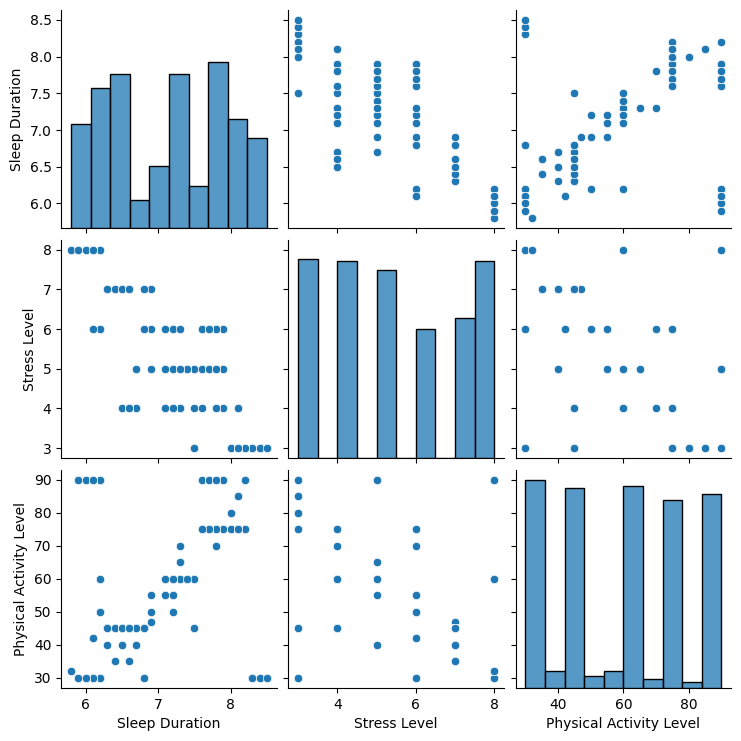

In [13]:
sns.pairplot(df[['Sleep Duration','Stress Level','Physical Activity Level']])

Scatterplot

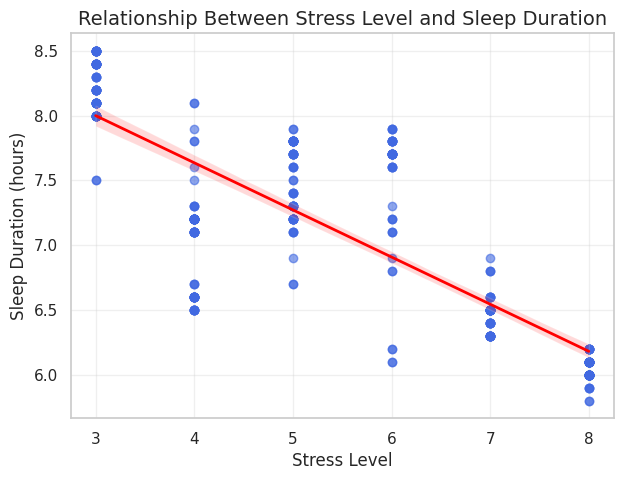

In [14]:
plt.figure(figsize=(7,5))
sns.set(style="whitegrid")

sns.regplot(data=df, x="Stress Level", y="Sleep Duration",
    scatter_kws={'alpha':0.6, 'color':'royalblue'},line_kws={'color':'red', 'linewidth':2})

plt.title("Relationship Between Stress Level and Sleep Duration", fontsize=14)
plt.xlabel("Stress Level", fontsize=12)
plt.ylabel("Sleep Duration (hours)", fontsize=12)
plt.grid(alpha=0.3)

plt.show()


Correlation Heatmap

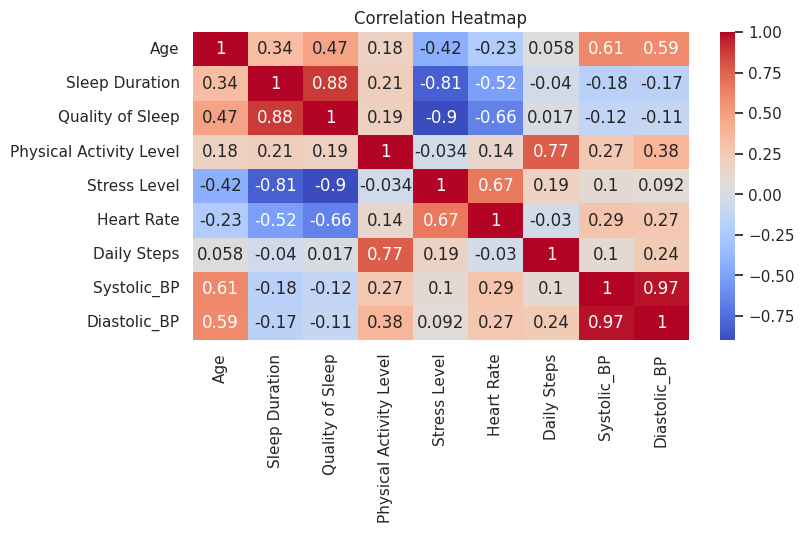

In [15]:
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

### 7. Elbow Method

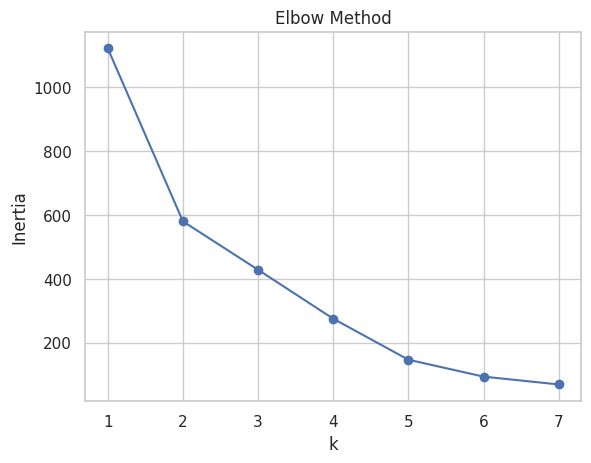

In [16]:
inertia = []
K = range(1, 8)

for k in K:
    km = KMeans(n_clusters=k, random_state=42).fit(scaled)
    inertia.append(km.inertia_)

plt.plot(K, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

### 8. K-Means Clustering

In [17]:
kmeans = KMeans(n_clusters=4, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled)

px.scatter(df, x='Sleep Duration', y='Stress Level', color=df['Cluster'],
           title="K-Means Cluster Visualization")

### 9. Silhouette Score

In [18]:
score = silhouette_score(scaled, df['Cluster'])
print(f"Silhouette Score: {score}")

Silhouette Score: 0.5707048574660717


### 10. Cluster Interpretation

In [19]:
# Cluster centroid values in original scale
centroids = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids)

centroid_df = pd.DataFrame(centroids_original, columns=features.columns)
centroid_df

,Sleep Duration,Stress Level,Physical Activity Level
0,7.475829,4.502370,68.388626
1,6.065625,8.000000,90.000000
2,6.302062,7.278351,38.865979
3,8.370588,3.000000,30.882353


### 11. Cluster Profiles

In [20]:
cluster_summary = df.groupby('Cluster')[['Sleep Duration','Stress Level','Physical Activity Level','Heart Rate',
'Systolic_BP','Diastolic_BP','Daily Steps']].mean()
display(cluster_summary)

,Sleep Duration,Stress Level,Physical Activity Level,Heart Rate,Systolic_BP,Diastolic_BP,Daily Steps
Cluster,,,,,,,
0,7.475829,4.502370,68.388626,68.810427,127.578199,84.341232,7155.924171
1,6.065625,8.000000,90.000000,75.000000,140.000000,95.000000,10000.000000
2,6.302062,7.278351,38.865979,73.226804,128.247423,83.536082,5604.123711
3,8.370588,3.000000,30.882353,65.294118,124.705882,80.000000,5176.470588


Sleep Disorder count per cluster

In [21]:
pd.crosstab(df['Cluster'], df['Sleep Disorder'])

Sleep Disorder,Insomnia,No Disorder,Sleep Apnea
Cluster,,,
0,30,143,38
1,1,2,29
2,45,41,11
3,1,33,0


Average health metrics per cluster

In [22]:
df.groupby('Cluster')[['Age','Heart Rate','Daily Steps','Systolic_BP','Diastolic_BP']].mean()

,Age,Heart Rate,Daily Steps,Systolic_BP,Diastolic_BP
Cluster,,,,,
0,41.606635,68.810427,7155.924171,127.578199,84.341232
1,49.750000,75.000000,10000.000000,140.000000,95.000000
2,37.659794,73.226804,5604.123711,128.247423,83.536082
3,51.558824,65.294118,5176.470588,124.705882,80.000000


Boxplot Examples

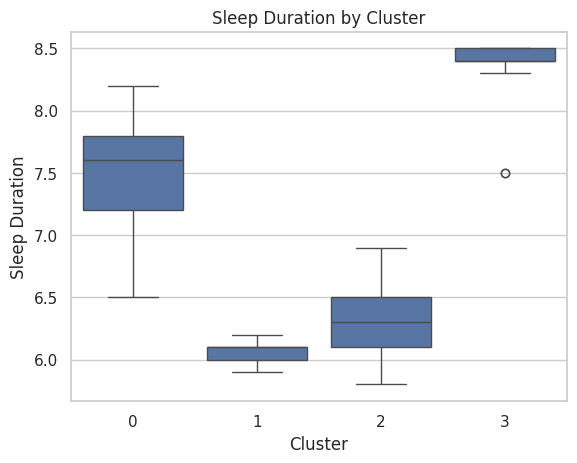

In [23]:
sns.boxplot(x='Cluster', y='Sleep Duration', data=df)
plt.title("Sleep Duration by Cluster")
plt.show()

### 12. Conclusion & Insights

### Key Insights

#### Cluster 0 (The Moderate / Balanced Group)
- Moderate sleep duration (~7.5 hours)
- Low-to-moderate stress levels
- Moderate physical activity
- Moderate rate of insomnia

#### Cluster 1 – High Stress & High Activity (Short Sleep)
- Lowest sleep duration (~6.1 hours)
- Highest stress levels (8.0/10)
- Very high physical activity and step count
- Highest blood pressure and strong propensity for Sleep Apnea

#### Cluster 2 – Moderate Group
- Shorter sleep duration (~6.3 hours)
- High stress levels
- Lower physical activity
- Highest rate of insomnia

#### Cluster 3 – Low Stress & Long Sleep
- Highest sleep duration (~8.4 hours)
- Lowest stress levels (3.0/10)
- Lowest physical activity level
- Excellent overall sleep profile with virtually no sleep disorders

## Summary
The clustering results strongly indicate that stress level and physical activity are the strongest predictors of sleep duration and sleep disorder type. People experiencing high stress consistently show:
- shorter sleep duration
- higher blood pressure
- higher likelihood of insomnia

## Conclusions:
- **Stress and Sleep Duration/Disorders:** Stress level emerges as a critical predictor. High stress is consistently associated with shorter sleep durations and a higher likelihood of sleep disorders, particularly insomnia. It also correlates with higher blood pressure.
- **Physical Activity and Sleep Disorders:** Physical activity level also plays a role, interacting with stress to define sleep patterns. While high activity combined with extreme stress (Cluster 1) is linked to Sleep Apnea, low stress combined with high sleep duration (Cluster 3) is associated with healthy sleep outcomes.
- **Cluster Profiles:** The four identified clusters effectively segment the population based on distinct combinations of sleep duration, stress levels, and physical activity, each with varying propensities for sleep disorders.

In essence, managing stress appears to be paramount for improving sleep duration and reducing the incidence of sleep disorders, while physical activity levels also contribute significantly to an individual's overall sleep health profile.


